<a href="https://colab.research.google.com/github/MarcoLuw/QoE-MOS-Prediction/blob/main/model_training/random_forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Feature description

| # | Column | Category | Meaning / Practical Use | Values / Details from README |
|---|--------|----------|--------------------------|------------------------------|
| 1 | id | Identifier | Unique identifier of the sample (one video-viewing test record). | Not further defined in README |
| 2 | user_id | Identifier | Identifier of the tester who performed the session; links multiple samples to the same person. | Not further defined in README |
| 3 | QoA_VLCresolution | Video (QoA) | The actual picture resolution at which the video was played in VLC during the session, i.e. how many vertical lines of detail were rendered on screen. In practice it tells you whether the user watched a lower-detail or higher-detail version of the clip. | README notes resolution is a class identifier with values 240p and 360p |
| 4 | QoA_VLCbitrate | Video (QoA) | The video bitrate reported by VLC, i.e. the amount of video data per second during playback; higher values mean more data and generally better image quality. | Not further defined in README |
| 5 | QoA_VLCframerate | Video (QoA) | The playback frame rate reported by VLC, i.e. how many video frames per second were shown; relates to motion smoothness. | Not further defined in README |
| 6 | QoA_VLCdropped | Video (QoA) | The count of video frames dropped by VLC during playback; a measure of rendering/decoding loss experienced by the user. | Not further defined in README |
| 7 | QoA_VLCaudiorate | Video (QoA) | The audio bitrate/rate reported by VLC for the session's sound track. | Not further defined in README |
| 8 | QoA_VLCaudioloss | Video (QoA) | The amount of audio lost during playback as reported by VLC; relates to sound dropouts. | Not further defined in README |
| 9 | QoA_BUFFERINGcount | Video (QoA) | The number of buffering (stalling) events that occurred during the video session; how many times playback paused to rebuffer. | Not further defined in README |
| 10 | QoA_BUFFERINGtime | Video (QoA) | The total time spent buffering/stalling during the session; the cumulative duration playback was interrupted. | Not further defined in README |
| 11 | QoS_type | Network (QoS) | The mobile network access technology used during the test. | Coded: 1=EDGE, 2=UMTS, 3=HSPA, 4=HSPAP, 5=LTE |
| 12 | QoS_operator | Network (QoS) | The French mobile network operator used for the session. | Coded: 1=SFR, 2=BOUYGUES, 3=ORANGE, 4=FREE |
| 13 | QoD_model | Device (QoD) | The model of the device (phone or tablet) used by the tester. | Not further defined in README |
| 14 | QoD_os-version | Device (QoD) | The Android OS version running on the test device. | Not further defined in README |
| 15 | QoD_api-level | Device (QoD) | The Android API level of the device (the platform API number associated with the OS version). | Not further defined in README |
| 16 | QoU_sex | User (QoU) | The tester's gender. | Coded: 0=Woman, 1=Man |
| 17 | QoU_age | User (QoU) | The tester's age. | README states testers were aged 19 to 38 |
| 18 | QoU_study | User (QoU) | The tester's highest education level. | Coded: 5=University, 4=Secondary school, 3=College, 2=Primary school, 1=Other |
| 19 | QoF_begin_time | Feedback (QoF) | The begin time of the video session (when the viewing started). | Not further defined in README |
| 20 | QoF_shift | Feedback (QoF) | A shift value related to the session. | Not further defined in README |
| 21 | QoF_audio | Feedback (QoF) | User feedback relating to the audio of the session. | Not further defined in README |
| 22 | QoF_video | Feedback (QoF) | User feedback relating to the video of the session. | Not further defined in README |
| 23 | MOS | Target / Score | Mean Opinion Score the tester gives at the end of each video view; the subjective quality rating used as the label. | Coded: 5=Excellent, 4=Good, 3=Fair, 2=Poor, 1=Bad |

# Download dataset

GitHub Link: https://github.com/Lamyne/Poqemon-QoE-Dataset

In [2]:
!wget https://raw.githubusercontent.com/Lamyne/Poqemon-QoE-Dataset/master/pokemon.csv -O ~/pokemon.csv
# !wget https://raw.githubusercontent.com/andreaaraldo/machine-learning-for-networks/master/course_library/visualization.py

--2026-11-10 20:56:26--  https://raw.githubusercontent.com/Lamyne/Poqemon-QoE-Dataset/master/pokemon.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 2606:50c0:8003::154, 2606:50c0:8002::154, 2606:50c0:8000::154, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|2606:50c0:8003::154|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 158675 (155K) [text/plain]
Saving to: ‘/mnt/hdd/homes/hlu/pokemon.csv’

/mnt/hdd/homes/hlu/ 100%[===================>] 154.96K  --.-KB/s    in 0.04s   

2026-11-10 20:56:26 (4.26 MB/s) - ‘/mnt/hdd/homes/hlu/pokemon.csv’ saved [158675/158675]



In [3]:
!uv pip install shap

Using Python 3.13.18 environment at: /mnt/hdd/homes/hlu/.venv
Checked 1 package in 519ms


In [4]:
!ls ~

QoE-MOS-Prediction		 my_job.sh
StereoQueerEval_EN_training.tsv	 my_script.py
StereoQueerEval_FA_training.tsv	 pokemon.csv
StereoQueerEval_IT_training.tsv	 semal27-stereoqueereval
StereoQueerEval_NL_training.tsv	 stereo_results
ds_result


# Python package import

In [5]:
import pandas as pd
import numpy as np
# import visualization
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix

from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.model_selection import train_test_split, RandomizedSearchCV, KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# The following is to be able to mount Google Drive
# from google.colab import drive
import pickle # To save the model
from os.path import isfile
from pathlib import Path
from datetime import datetime

# Artifact location

In [6]:
FEATURES = ["QoA_VLCresolution", "QoA_VLCbitrate", "QoA_VLCframerate",
            "QoA_VLCdropped", "QoA_VLCaudiorate", "QoA_VLCaudioloss",
            "QoA_BUFFERINGcount", "QoA_BUFFERINGtime", "QoD_model", "QoU_sex", "QoU_age", "QoU_Ustedy"]
TARGET = "MOS"

In [7]:
model_tag = "RF-with-QoA-QoU"
model_artifact = f'{model_tag}.pkl'

# Timestamp for this run, to avoid overwriting previous runs
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

# Always under home, in a dedicated results folder
SAVE_PATH = Path.home() / "ds_result" / timestamp
SAVE_PATH.mkdir(parents=True, exist_ok=True)

In [8]:
df = pd.read_csv("~/pokemon.csv")

In [9]:
df.head()

,id,user_id,QoA_VLCresolution,QoA_VLCbitrate,QoA_VLCframerate,QoA_VLCdropped,QoA_VLCaudiorate,QoA_VLCaudioloss,QoA_BUFFERINGcount,QoA_BUFFERINGtime,...,QoD_os-version,QoD_api-level,QoU_sex,QoU_age,QoU_Ustedy,QoF_begin,QoF_shift,QoF_audio,QoF_video,MOS
0,590,71,360,528.39294,24.950000,0,43.800000,0,2,683,...,4.1.1(122573.16),16,1,20,5,3,5,3,4,3
1,428,46,360,402.64664,30.066667,0,44.200000,0,2,690,...,4.4.2(I9195XXUCNK1),19,1,25,5,4,5,5,5,5
2,406,44,360,735.84070,24.200000,0,44.183333,0,2,840,...,4.1.2(I9300XXELL4),16,1,22,5,3,5,4,4,4
3,1256,133,240,529.48830,24.116667,9,43.850000,0,2,868,...,4.4.4(suv3Rw),19,1,31,5,4,5,5,5,5
4,244,22,360,736.00085,24.066667,0,43.850000,0,2,869,...,4.1.2(I9300XXELL4),16,0,26,5,5,5,4,5,5


# Data Preprocessing

- Remove duplications
- Remove error values
- Handle missing values

In [10]:
def preprocess(df):
  df = df.drop_duplicates(keep="first") # drop duplications
  df = df[df["QoA_VLCresolution"] != 16]  # drop error values
  df = df.dropna(subset=FEATURES + [TARGET]) # drop missing values
  df = df.reset_index(drop=True)

  X = df[FEATURES]
  y = df[TARGET]
  return X, y

# Prepare data

In [11]:
def prepare_data(X, y):
  X_train, X_test, y_train, y_test = train_test_split(
      X, y, test_size=0.2, random_state=42
  )

  # feature engineering: transform (de-skew) - no need for Random Forest
  # pt = PowerTransformer(method="yeo-johnson")
  # X_train = pt.fit_transform(X_train)
  # X_test = pt.transform(X_test)

  # scale
  scaler = StandardScaler()
  X_train = scaler.fit_transform(X_train)
  X_test = scaler.transform(X_test)

  return X_train, X_test, y_train, y_test, scaler

In [12]:
X, y = preprocess(df)
X_train, X_test, y_train, y_test, scaler = prepare_data(X, y)

# Training a random forest

## Define grid params

In [13]:
# number of trees
n_estimators = [100, 300, 500]

# max number of features to consider at every split
max_features = ['sqrt', 'log2', 1.0]

# max number of levels in tree
max_depth = [5, 10, 20, 50, 100, None]

# Minimum number of samples required to split a node
min_samples_split = [2, 5, 10, 15, 20]

# Minimum number of samples required at each leaf node
min_samples_leaf = [1, 2, 5, 10, 15]

# Maximum number of allowed leafs
max_leaf_nodes = [16, 32, 64, 128, 256, 512, 1024, 2048]

# Criterion (regression: error measures, not gini/entropy)
criterion = ['squared_error', 'absolute_error']

# Minimum quality threshold for a split
# Ex. If impurity decrease < 0.1 -> SPLIT rejected
min_impurity_decrease = [0, 0.001, 0.01, 0.1, 0.2]

grid_param = {
    'n_estimators': n_estimators,
    'max_features': max_features,
    'max_depth': max_depth,
    'min_samples_split': min_samples_split,
    'min_samples_leaf': min_samples_leaf,
    'max_leaf_nodes': max_leaf_nodes,
    'criterion': criterion,
    'min_impurity_decrease': min_impurity_decrease,
}

## Random Grid Search

It's roughly **216,000 combinations x 5 k-fold** to be evaluated, a very large computational expense.

`RandomizedSearchCV` helps to overcome the hurdle by randomly sampling a specified number of possible candidate models.

For example, only randomly sample 100 models:
```python
search = RandomizedSearchCV(
    n_iter=50 # We just test 50 configurations
  )
```

In [14]:
# The search parallelizes across 200x5 fits (all CPUs) (n_jobs = -1)
# while each individual forest trains single-threaded (n_jobs = 1)
regressor = RandomForestRegressor(random_state=42, n_jobs=1)
search = RandomizedSearchCV(
                            scoring='neg_root_mean_squared_error',
                            estimator=regressor,
                            param_distributions=grid_param,
                            n_iter=300, # We just test 200 configurations
                            verbose=2,
                            random_state=42, # Random state of GridSearch only
                            n_jobs=-1, # Train forests in parallel using all CPUs
                            cv=5 # 5-fold validation
                          )

In [15]:
search.fit(X_train, y_train)

Fitting 5 folds for each of 300 candidates, totalling 1500 fits
[CV] END criterion=squared_error, max_depth=10, max_features=1.0, max_leaf_nodes=64, min_impurity_decrease=0, min_samples_leaf=10, min_samples_split=2, n_estimators=100; total time=   0.2s
[CV] END criterion=squared_error, max_depth=5, max_features=sqrt, max_leaf_nodes=64, min_impurity_decrease=0.001, min_samples_leaf=5, min_samples_split=5, n_estimators=500; total time=   0.4s
[CV] END criterion=absolute_error, max_depth=None, max_features=log2, max_leaf_nodes=256, min_impurity_decrease=0.01, min_samples_leaf=5, min_samples_split=20, n_estimators=500; total time=   0.9s
[CV] END criterion=absolute_error, max_depth=20, max_features=log2, max_leaf_nodes=256, min_impurity_decrease=0.2, min_samples_leaf=2, min_samples_split=5, n_estimators=500; total time=   0.5s
[CV] END criterion=absolute_error, max_depth=5, max_features=sqrt, max_leaf_nodes=64, min_impurity_decrease=0.001, min_samples_leaf=15, min_samples_split=2, n_estima

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'criterion': ['squared_error', 'absolute_error'], 'max_depth': [5, 10, ...], 'max_features': ['sqrt', 'log2', ...], 'max_leaf_nodes': [16, 32, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",300
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator,

## Get best model

In [16]:
print(search.best_params_)
best_model = search.best_estimator_

{'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'min_impurity_decrease': 0.001, 'max_leaf_nodes': 256, 'max_features': 'sqrt', 'max_depth': None, 'criterion': 'squared_error'}


With this best model, we try to (re)train it on the whole dataset

In [17]:
best_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",256
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.001
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",

# Evaluating Model

In [36]:
y_pred = best_model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Save metrics to CSV
results = pd.DataFrame({
    "Metric": ["RMSE", "MAE", "R2"],
    "Score": [rmse, mae, r2]
})

results.to_csv(SAVE_PATH / "evaluation_results.csv", index=False)

print(results)

  Metric     Score
0   RMSE  0.729326
1    MAE  0.492644
2     R2  0.539498

[CV] END criterion=absolute_error, max_depth=10, max_features=1.0, max_leaf_nodes=128, min_impurity_decrease=0.2, min_samples_leaf=5, min_samples_split=20, n_estimators=100; total time=   0.2s
[CV] END criterion=squared_error, max_depth=None, max_features=1.0, max_leaf_nodes=256, min_impurity_decrease=0.01, min_samples_leaf=1, min_samples_split=20, n_estimators=100; total time=   0.2s
[CV] END criterion=squared_error, max_depth=None, max_features=1.0, max_leaf_nodes=256, min_impurity_decrease=0.01, min_samples_leaf=1, min_samples_split=20, n_estimators=100; total time=   0.1s
[CV] END criterion=absolute_error, max_depth=100, max_features=1.0, max_leaf_nodes=1024, min_impurity_decrease=0.1, min_samples_leaf=5, min_samples_split=2, n_estimators=300; total time=   0.9s
[CV] END criterion=squared_error, max_depth=10, max_features=log2, max_leaf_nodes=32, min_impurity_decrease=0.2, min_samples_leaf=1, min_samples_s

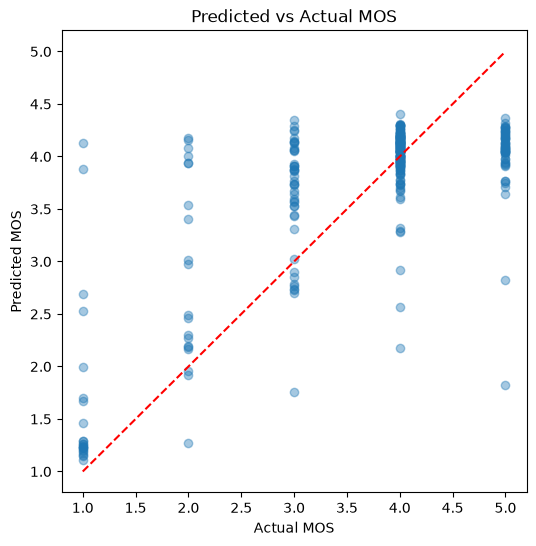

In [19]:
# Predicted vs actual MOS
title = "Predicted vs Actual MOS"
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.4)

# diagonal reference line (perfect prediction)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, 'r--')

plt.xlabel("Actual MOS")
plt.ylabel("Predicted MOS")
plt.title(title)
plt.savefig(SAVE_PATH / "pred_vs_actual.png", dpi=150, bbox_inches="tight")  # save
plt.show()

# Model Explanation

## Feature importance (impurity-based)

In [20]:
importances = pd.Series(
    best_model.feature_importances_,
    index=FEATURES
).sort_values(ascending=False)

print(importances)

QoA_BUFFERINGtime     0.404106
QoA_VLCframerate      0.209817
QoA_VLCaudiorate      0.095843
QoA_VLCbitrate        0.084258
QoA_BUFFERINGcount    0.083382
QoU_age               0.041125
QoA_VLCaudioloss      0.028480
QoA_VLCdropped        0.026075
QoA_VLCresolution     0.010526
QoU_sex               0.009173
QoU_Ustedy            0.007214
dtype: float64


In [21]:
# Frequency per value of a column (check for high cardinality feature)
df["QoA_BUFFERINGtime"].value_counts().sort_index()

QoA_BUFFERINGtime
683       1
690       1
840       1
868       1
869       1
         ..
120628    1
123318    1
123430    1
139610    1
329271    1
Name: count, Length: 1327, dtype: int64

In [22]:
df["QoA_VLCframerate"].value_counts().sort_index()

QoA_VLCframerate
0.000000     2
0.050000     1
0.133333     3
0.200000     1
0.216667     1
            ..
31.100000    2
31.116667    1
31.150000    1
31.216667    1
31.316667    1
Name: count, Length: 309, dtype: int64

We observe that:
- `QoA_BUFFERINGtime` and `QoA_VLCframerate` have high feature importance weights (0.579337 and 0.131076).
- `QoA_BUFFERINGtime` and `QoA_VLCframerate` are also high cardinality features (1327 and 309 unique values)

Based on the [feature importance document](https://scikit-learn.org/stable/auto_examples/ensemble/plot_forest_importances.html#feature-importance-based-on-mean-decrease-in-impurity), impurity-based feature importances can be misleading for high cardinality features. 

Therefore, we are not confident that the two top-weighted features are important for predicting MOS.

=> We will alternatively use [Permutation feature importance](https://scikit-learn.org/stable/modules/permutation_importance.html#permutation-importance)

In [23]:
importances.to_csv(SAVE_PATH / "importance_builtin.csv")  # save built-in importance table

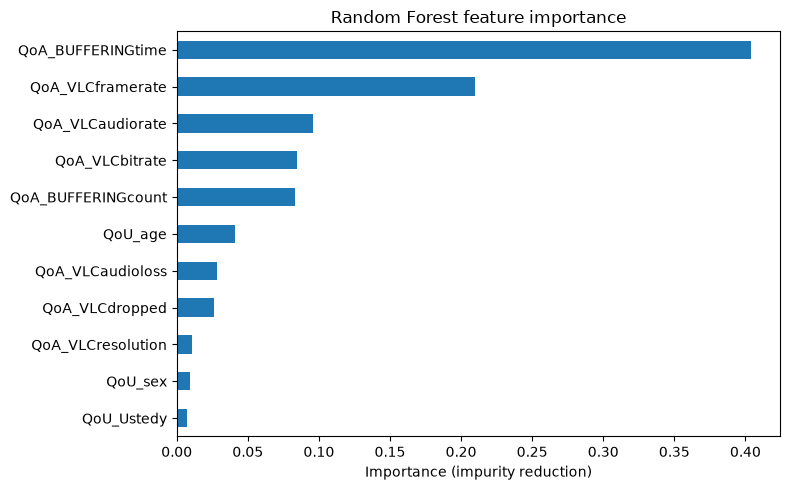

In [24]:
importances.sort_values().plot(kind="barh", figsize=(8, 5))
plt.xlabel("Importance (impurity reduction)")
plt.title("Random Forest feature importance")
plt.tight_layout()
plt.savefig(SAVE_PATH / "importance_builtin.png", dpi=150, bbox_inches="tight")  # save plot
plt.show()

## Permutation importance

Permutation feature importance reflects how important a feature is for a particular model

In this case, we use `scoring=rmse` for a regression model

In [25]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    best_model, X_test, y_test,
    scoring="neg_root_mean_squared_error",
    n_repeats=20,
    random_state=42,
    n_jobs=-1,
)

perm = pd.Series(
    result.importances_mean,
    index=FEATURES
).sort_values(ascending=False)

print(perm)

QoA_BUFFERINGtime     0.269853
QoA_VLCframerate      0.102979
QoA_VLCaudiorate      0.039489
QoA_BUFFERINGcount    0.018593
QoA_VLCbitrate        0.005447
QoA_VLCaudioloss      0.003051
QoU_sex               0.003002
QoU_age               0.002974
QoA_VLCresolution     0.001698
QoU_Ustedy            0.001216
QoA_VLCdropped        0.000930
dtype: float64


From the table above, we observe that `QoA_BUFFERINGtime` and `QoA_VLCframerate` are actually important for the RF model
- `QoF_begin` and `QoF_shift` are secondarily important, but since our objective is to predict the MOS based on the network condition, these two user feedback features, together with `QoF_video` and `QoF_audio` will be removed due to their data leakage and irrelevance
- `QoA_BUFFERINGtime` has higher importance than `QoA_BUFFERINGcount` -> total duration of buffering (user waiting time) provides more useful predictive information
- User profile features somehow have higher average importance than video parameters and network information -> Diversity in user background could have a more substantial impact on MOS scores (their experiences and perspectives). Though both user and network profiles seem to have little effect on MOS prediction

In [26]:
# save permutation importance table
perm_df = pd.DataFrame({
    "importance_mean": result.importances_mean,
    "importance_std": result.importances_std,
}, index=FEATURES).sort_values("importance_mean", ascending=False)
perm_df.to_csv(SAVE_PATH / "importance_permutation.csv")

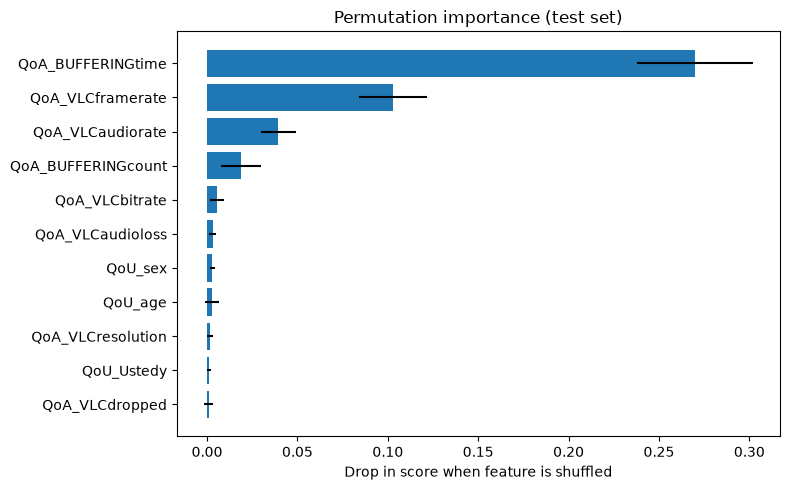

In [27]:
sorted_idx = result.importances_mean.argsort()

plt.figure(figsize=(8, 5))
plt.barh(
    np.array(FEATURES)[sorted_idx],
    result.importances_mean[sorted_idx],
    xerr=result.importances_std[sorted_idx],
)
plt.xlabel("Drop in score when feature is shuffled")
plt.title("Permutation importance (test set)")
plt.tight_layout()
plt.savefig(SAVE_PATH / "importance_permutation.png", dpi=150, bbox_inches="tight")  # save plot
plt.show()

## SHAP

So far, we have known how importance each feature are thanks to both built-in (impurity-based) and permutation feature importances.
But they lack the direction of the importance, for example, whether higher BufferingTime provides higher or lower MOS.

=> SHAP can help: giving direction and per-sample effects to the model

In [28]:
import shap

# Build the explainer
explainer = shap.TreeExplainer(best_model)
X_test_df_shap = pd.DataFrame(X_test, columns=FEATURES)
shap_values = explainer.shap_values(X_test_df_shap)

/mnt/hdd/homes/hlu/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


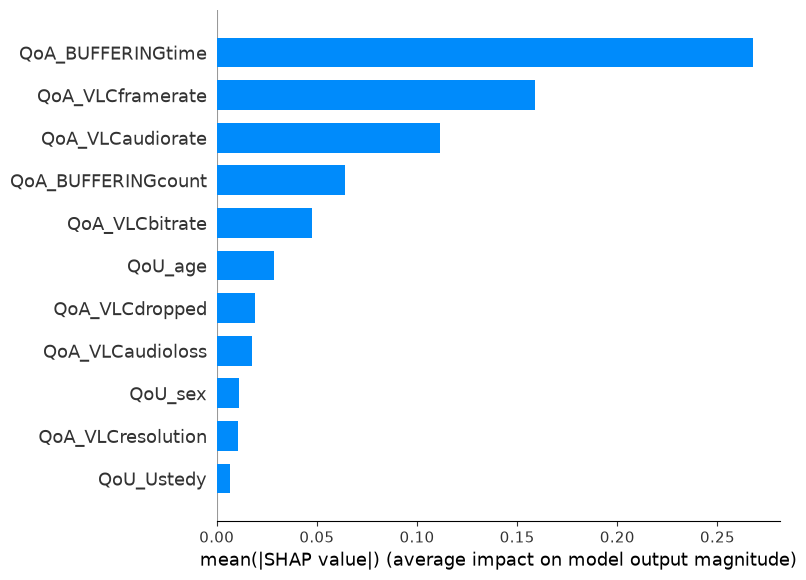

In [29]:
shap.summary_plot(shap_values, X_test_df_shap, plot_type="bar")

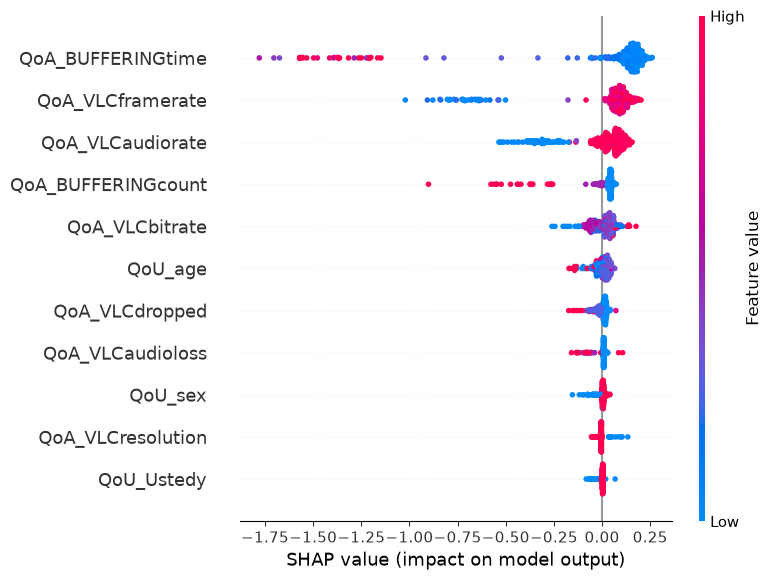

In [30]:
# Save and show SHAP beeswarm plot
shap.summary_plot(shap_values, X_test_df_shap, show=False)
plt.tight_layout()
plt.savefig(SAVE_PATH / "shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

# Save model

## On Google Colab

In [31]:
# mount_point = '/content/drive'
# drive.mount(mount_point, force_remount=True)
# drive_path = mount_point + '/My Drive/'

# save_path = drive_path + 'Colab Notebooks/TSP - Data Science/Project/Models/'
# filename = save_path + f'RF.pkl'
# pickle.dump(best_model, open(filename, 'wb'))

In [32]:
# %cd $save_path
# !ls

Optional: create a function to reduce duplication

In [33]:
# def search_or_load(model_filename, search, X_train, y_train):
#   if (isfile(model_filename)):
#     print("Loading model")
#     model = pickle.load(open(model_filename, 'rb'))

#   else:
#     print("Searching the best hyper_parameters")
#     search.fit(X_train, y_train)
#     print(search.best_params_)
#     model = search.best_estimator_
#     print("Training model")
#     model.fit(X_train,y_train)
#     pickle.dump(model, open(model_filename, 'wb'))
#     print("Model saved in in file ", model_filename)
#   return model

## On Linux

In [34]:
FINAL_MODEL_PATH = str(SAVE_PATH / model_artifact)

pickle.dump(best_model, open(FINAL_MODEL_PATH, 'wb'))

print("Final model path:", FINAL_MODEL_PATH)

Final model path: /mnt/hdd/homes/hlu/ds_result/20261110_205635/RF-with-QoA-QoU.pkl
